# E-Commerce Customer Segmentation (RFM + K-Means + DBSCAN + PCA + t-SNE)
**Author:** Utkarsh Singh

**Business problem:** An online retailer wants to stop sending the same campaign to everyone. We group customers by *how recently* (Recency), *how often* (Frequency) and *how much* (Monetary) they buy, then turn each group into an actionable marketing persona.

**Pipeline:** transactions -> RFM table -> log + standardise -> PCA -> K-Means (elbow + silhouette) -> DBSCAN (k-distance) -> t-SNE visualisation -> personas and actions.

> **Data note:** the notebook uses `data/online_retail.csv` (UCI Online Retail) if present. Otherwise it generates synthetic transactions with the identical schema, so the notebook always runs end to end.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score
import rfm_segmentation as rs
pd.set_option("display.width", 200)
%matplotlib inline

## 1. Load transactions and build the RFM table
* **Recency** = days since the customer's last purchase (lower is better), measured from a snapshot date (last invoice date + 1 day).
* **Frequency** = number of distinct invoices.
* **Monetary** = total revenue (`Quantity x UnitPrice`).

Cleaning (real data): drop rows with missing `CustomerID`, cancelled invoices (start with `C`), and non-positive quantity or price.

In [2]:
df, src = rs.load_transactions()
print("Source:", src, "| rows:", len(df))
df.head()

Source: Synthetic transactions (same schema as UCI Online Retail) | rows: 54516


,InvoiceNo,CustomerID,InvoiceDate,Quantity,UnitPrice
0,INV12001-0,12001,2011-10-22 07:18:52.992217288,2,12.79
1,INV12001-0,12001,2011-10-22 07:18:52.992217288,9,20.94
2,INV12001-1,12001,2011-09-21 15:48:28.705064340,10,38.08
3,INV12001-1,12001,2011-09-21 15:48:28.705064340,5,36.19
4,INV12001-1,12001,2011-09-21 15:48:28.705064340,9,43.10


In [3]:
rfm = rs.build_rfm(df)
print(rfm.shape)
rfm.describe().round(2)

(3000, 3)


,Recency,Frequency,Monetary
count,3000.00,3000.00,3000.00
mean,99.30,4.54,2075.92
std,108.38,4.42,3116.15
min,1.00,1.00,4.70
25%,19.00,1.00,289.56
50%,53.50,3.00,719.47
75%,142.00,6.00,2251.67
max,360.00,24.00,19445.05


## 2. Pre-processing: log transform and scaling
Frequency and Monetary are strongly **right-skewed** (a few huge buyers). Distance-based algorithms (K-Means, DBSCAN, t-SNE) are dominated by large-scale features, so we:
1. apply `log1p` to reduce skew, then
2. apply `StandardScaler` (mean 0, std 1) so R, F, M contribute equally.

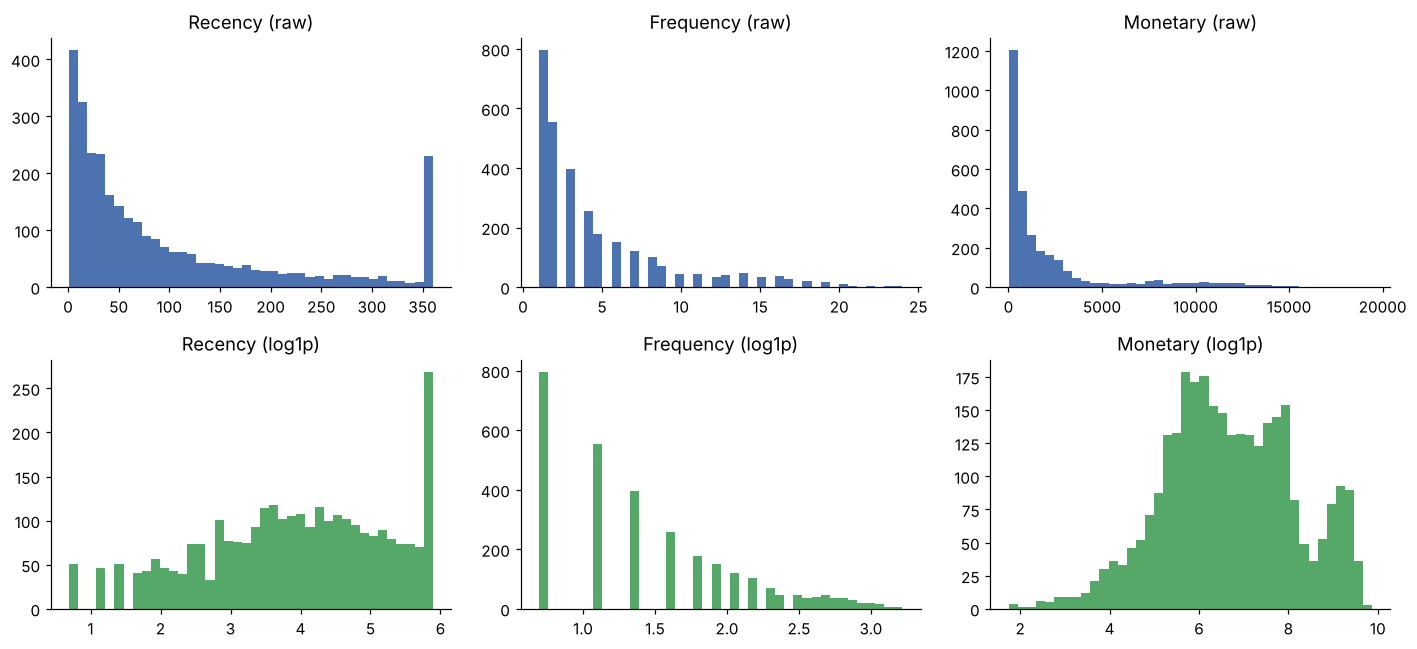

In [4]:
logged, X = rs.preprocess(rfm)
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for i, c in enumerate(rfm.columns):
    ax[0, i].hist(rfm[c], bins=40, color="#4C72B0"); ax[0, i].set_title(f"{c} (raw)")
    ax[1, i].hist(logged[c], bins=40, color="#55A868"); ax[1, i].set_title(f"{c} (log1p)")
plt.tight_layout(); plt.show()

## 3. PCA (dimensionality reduction)
PCA finds orthogonal directions of maximum variance. With only 3 features the aim is mainly a **2-D view** and to understand which features drive variation (loadings).

In [5]:
pca_full = PCA().fit(X)
evr = pca_full.explained_variance_ratio_
print("Explained variance ratio:", evr.round(3), "| cumulative:", np.cumsum(evr).round(3))

pca2 = PCA(n_components=2, random_state=42)
P = pca2.fit_transform(X)
pd.DataFrame(pca2.components_.T, index=rfm.columns, columns=["PC1", "PC2"]).round(3)

Explained variance ratio: [0.673 0.284 0.043] | cumulative: [0.673 0.957 1.   ]


,PC1,PC2
Recency,-0.357,0.933
Frequency,0.666,0.217
Monetary,0.655,0.289


**Reading the loadings:** PC1 is large and positive for Frequency and Monetary (an overall *customer value* axis). PC2 is dominated by Recency (a *how recently active* axis). Two components capture about 96% of the variance, so the 2-D PCA plot loses little information.

## 4. K-Means: choosing k
* **Elbow method:** plot inertia (within-cluster sum of squares) vs k; look for the bend.
* **Silhouette score:** how well each point fits its cluster vs the nearest other cluster (-1 to 1, higher is better).
* **Davies-Bouldin:** lower is better.

Silhouette alone slightly favours k=2 (just "active" vs "inactive"), which is too coarse for marketing. We restrict k to **4-6** and choose by silhouette within that range. k=4 also has the best Davies-Bouldin score.

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,4813.539,0.401,0.963,2607.441
1,3,3539.656,0.349,1.015,2311.618
2,4,2622.947,0.346,0.931,2428.016
3,5,2231.934,0.326,0.967,2270.506
4,6,1915.478,0.312,0.966,2214.737
5,7,1686.741,0.322,0.924,2162.812
6,8,1491.931,0.322,0.920,2151.014
7,9,1369.753,0.312,0.916,2082.688


Chosen k = 4


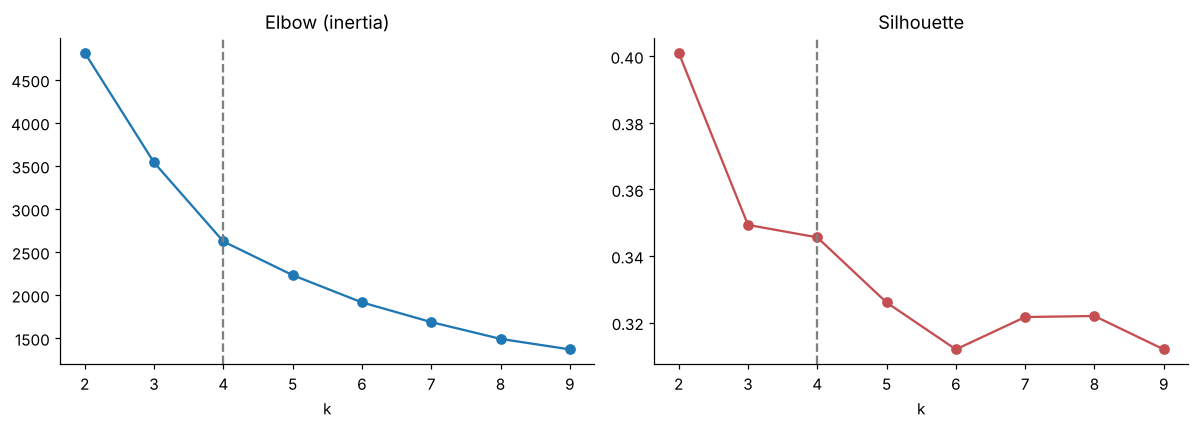

In [6]:
ks = rs.choose_k(X)
display(ks.round(3))
best_k = int(ks[ks.k.between(4, 6)].sort_values("silhouette", ascending=False).iloc[0].k)
print("Chosen k =", best_k)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks.k, ks.inertia, "o-"); ax[0].axvline(best_k, ls="--", c="grey"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(ks.k, ks.silhouette, "o-", c="#C44E52"); ax[1].axvline(best_k, ls="--", c="grey"); ax[1].set_title("Silhouette")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

In [7]:
km = KMeans(n_clusters=best_k, n_init=20, random_state=42).fit(X)
rfm["KMeans"] = km.labels_
print("Silhouette:", round(silhouette_score(X, km.labels_), 3),
      "| Davies-Bouldin:", round(davies_bouldin_score(X, km.labels_), 3))

Silhouette: 0.346 | Davies-Bouldin: 0.931


## 5. DBSCAN (density-based clustering)
DBSCAN needs `eps` (neighbourhood radius) and `min_samples`. A common heuristic is the **k-distance graph**: sort each point's distance to its k-th neighbour and pick `eps` near the "knee". Points in sparse regions become **noise (-1)**, which is useful for spotting outliers (e.g., extreme big spenders). We also grid-search `eps` / `min_samples` by silhouette on non-noise points.

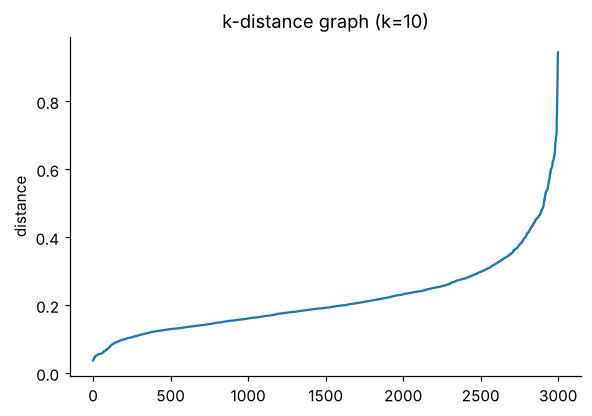

Best DBSCAN: eps=0.5, min_samples=10, clusters=2, noise=0.8%, silhouette=0.271


DBSCAN
 0    2189
 1     787
-1      24
Name: count, dtype: int64

In [8]:
kdist, best = rs.tune_dbscan(X)
plt.figure(figsize=(6, 4)); plt.plot(kdist); plt.title("k-distance graph (k=10)"); plt.ylabel("distance"); plt.show()
s, eps, ms, ncl, noise = best
print(f"Best DBSCAN: eps={eps}, min_samples={ms}, clusters={ncl}, noise={noise:.1%}, silhouette={s:.3f}")
rfm["DBSCAN"] = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
rfm["DBSCAN"].value_counts()

**K-Means vs DBSCAN here:** RFM data forms one continuous cloud rather than clearly separated dense blobs, so DBSCAN finds only a few large density regions plus a small noise set. K-Means partitions the cloud into the more granular groups marketing needs. DBSCAN is still valuable as an **outlier detector** and as a cross-check of the broad structure (active vs inactive).

## 6. Visualisation: PCA and t-SNE
t-SNE is a non-linear method that preserves *local* neighbourhoods. It is for **visualisation only**: distances between far-apart clusters and cluster sizes are not meaningful, and results depend on `perplexity` and the random seed.

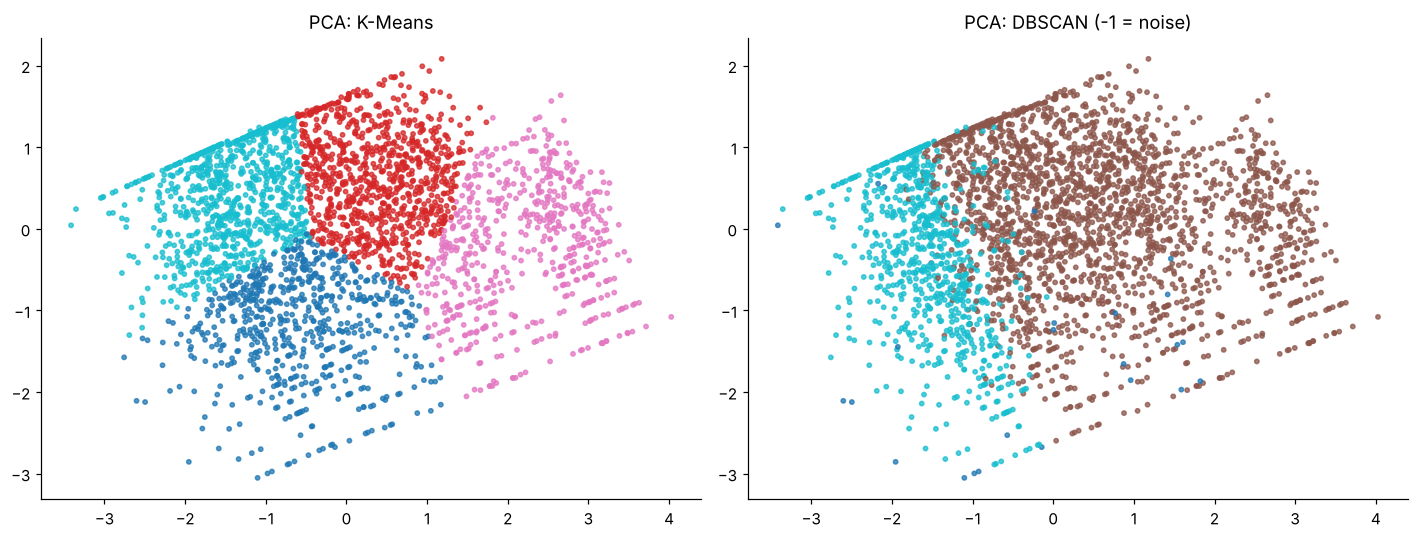

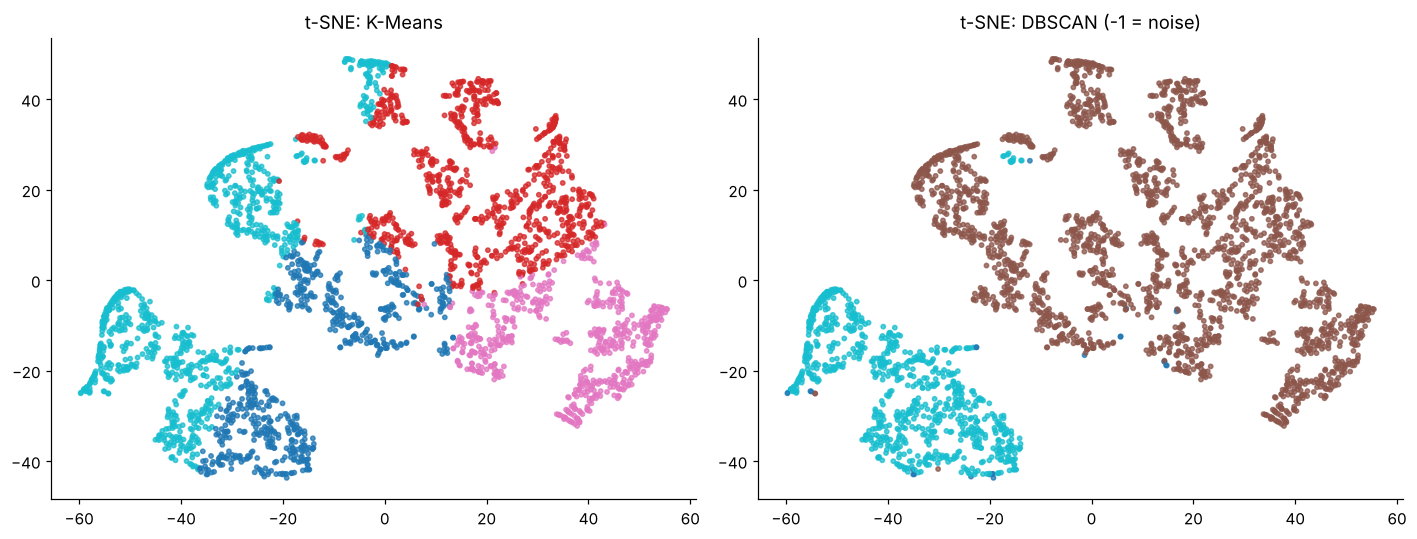

In [9]:
T = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=42).fit_transform(X)

def pair(coords, name):
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    for a, lab, t in ((ax[0], rfm.KMeans.values, "K-Means"), (ax[1], rfm.DBSCAN.values, "DBSCAN (-1 = noise)")):
        a.scatter(coords[:, 0], coords[:, 1], c=lab, cmap="tab10", s=8, alpha=.75); a.set_title(f"{name}: {t}")
    plt.tight_layout(); plt.show()
pair(P, "PCA"); pair(T, "t-SNE")

## 7. Cluster profiles and marketing personas
We profile each K-Means cluster in the **original RFM units**, compute its share of customers and share of revenue, then name it using simple, explainable rules (relative to the median R, F, M).

In [10]:
prof = rfm.groupby("KMeans")[["Recency", "Frequency", "Monetary"]].mean()
prof["Customers"] = rfm.groupby("KMeans").size()
prof["Share_%"] = (prof.Customers / prof.Customers.sum() * 100).round(1)
prof["Revenue_share_%"] = (rfm.groupby("KMeans").Monetary.sum() / rfm.Monetary.sum() * 100).round(1)
names = rs.name_personas(prof)
prof["Persona"] = prof.index.map(names)
prof["Action"] = prof.Persona.map(rs.action_for)
rfm["Persona"] = rfm.KMeans.map(names)
prof.drop(columns="Action").round(1)

,Recency,Frequency,Monetary,Customers,Share_%,Revenue_share_%,Persona
KMeans,,,,,,,
0,18.9,1.8,431.6,651,21.7,4.5,New / Promising
1,118.3,4.8,1898.5,890,29.7,27.1,At-Risk Big Spenders
2,19.0,11.7,6840.1,582,19.4,63.9,Champions
3,192.9,1.5,314.9,877,29.2,4.4,Hibernating / Lost


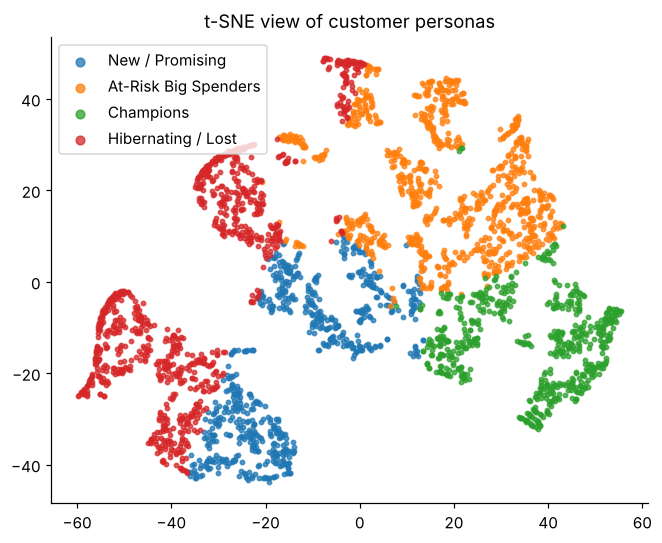

In [11]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for c in sorted(names):
    m = rfm.KMeans.values == c
    ax.scatter(T[m, 0], T[m, 1], s=8, alpha=.75, label=names[c])
ax.legend(markerscale=2); ax.set_title("t-SNE view of customer personas"); plt.show()

## 8. Personas and recommended actions

In [12]:
for c, r in prof.sort_values("Revenue_share_%", ascending=False).iterrows():
    print(f"\n{r.Persona}  ({r['Share_%']}% of customers, {r['Revenue_share_%']}% of revenue)")
    print(f"  Avg recency {r.Recency:.0f} days | avg orders {r.Frequency:.1f} | avg spend {r.Monetary:,.0f}")
    print("  Action:", r.Action)


Champions  (19.4% of customers, 63.9% of revenue)
  Avg recency 19 days | avg orders 11.7 | avg spend 6,840
  Action: VIP programme, early access to launches, referral rewards. Do not discount; reward loyalty.

At-Risk Big Spenders  (29.7% of customers, 27.1% of revenue)
  Avg recency 118 days | avg orders 4.8 | avg spend 1,899
  Action: Personal win-back outreach, high-value coupon, 'we miss you' campaign, feedback survey.

New / Promising  (21.7% of customers, 4.5% of revenue)
  Avg recency 19 days | avg orders 1.8 | avg spend 432
  Action: Welcome series, second-purchase incentive within 30 days, onboarding emails.

Hibernating / Lost  (29.2% of customers, 4.4% of revenue)
  Avg recency 193 days | avg orders 1.5 | avg spend 315
  Action: Low-cost reactivation email, clearance offers; suppress after 2 failed attempts to save budget.


## 9. Conclusions
* A small group of **Champions** (~19% of customers) generates roughly **two-thirds of revenue**: retention of this group is the top priority.
* **At-Risk Big Spenders** have solid past value but are drifting away (long recency): the best target for win-back campaigns.
* **New / Promising** customers are recent but have few orders: the goal is a fast second purchase.
* **Hibernating / Lost** customers are numerous but contribute little: use cheap, automated reactivation only.
* PCA showed the data has two main axes (value and recency); t-SNE confirmed the K-Means groups occupy distinct regions; DBSCAN highlighted the continuous nature of RFM data and flagged outliers.

**Limitations / next steps:** RFM ignores product mix and returns; try RFM quintile scoring, Gaussian Mixture Models, or add features (basket size, category). Validate personas with an A/B campaign test.